<a href="https://colab.research.google.com/github/jessicalewinter/deep-learning-specialization/blob/main/course-notebooks/neural-networks/Lab4_Otimizacao_e_Inicializacao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratório 4 — Otimização e Inicialização

**Fundamentos de Redes Neurais Artificiais** · Aula 4

---

O roteiro acompanha a aula:

1. **Recarregar os Labs 2 e 3**: ativações, perdas, forward e backward, sem alteração.
2. **Gradiente descendente à mão**: o vale ℒ = w₁² + 4w₂² dos slides, com η = 0,1 e η = 0,3.
3. **Inicialização**: uma função com zeros, escala fixa, Xavier e He.
4. **Bloco 1 — A classe MLP**: forward, backward, passo e treinar num objeto só.
5. **Bloco 2 — O treino completo**: mini-lotes de 64, η = 0,1, He e ReLU nos dígitos.
6. **Bloco 3 — Taxa de aprendizagem**: cinco valores de η, mesma rede.
7. **Bloco 4 — Tamanho do lote**: lote inteiro, estocástico e mini-lote.
8. **Bloco 5 — Inicialização**: zeros, σ = 1, Xavier e He; e o sinal atravessando dez camadas.
9. **Bloco 6 — Momentum**: no vale dos slides e nos dígitos.
10. **Os erros da rede**: matriz de confusão e as imagens que ela ainda erra.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, VERMELHO, VERDE, TINTA, CINZA = "#7C90B0", "#DB1E2F", "#2E8B8B", "#231F20", "#5F5A5C"
print("pronto")

pronto


## 1. Recarregando os Labs 2 e 3

As funções abaixo são as mesmas das aulas anteriores, sem nenhuma alteração: as ativações com suas derivadas,
a softmax, a entropia cruzada, o one-hot, o *forward* e o *backward*. Hoje elas vão para dentro de uma classe.

In [2]:
def sigmoid(Z):
    return 1 / (1 + np.exp(-Z))

def relu(Z):
    return np.maximum(0, Z)

ATIVACOES = {
    'sigmoid': (sigmoid, lambda Z: sigmoid(Z) * (1 - sigmoid(Z))),
    'tanh':    (np.tanh, lambda Z: 1 - np.tanh(Z) ** 2),
    'relu':    (relu,    lambda Z: (Z > 0).astype(float)),
}

def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

def cce(Y, Y_hat, eps=1e-12):
    Y_hat = np.clip(Y_hat, eps, 1.0)
    return -np.mean(np.sum(Y * np.log(Y_hat), axis=1))

def one_hot(y, k):
    Y = np.zeros((len(y), k))
    Y[np.arange(len(y)), y] = 1
    return Y

def forward(X, params, ativacao='relu'):                     # Lab 2
    g, _ = ATIVACOES[ativacao]
    L = len(params) // 2
    cache = {'A0': X}
    A = X
    for l in range(1, L):
        Z = A @ params[f'W{l}'] + params[f'b{l}']
        A = g(Z)
        cache[f'Z{l}'], cache[f'A{l}'] = Z, A
    ZL = A @ params[f'W{L}'] + params[f'b{L}']
    AL = softmax(ZL)
    cache[f'Z{L}'], cache[f'A{L}'] = ZL, AL
    return AL, cache

def backward(Y, params, cache, ativacao='relu'):            # Lab 3
    _, dg = ATIVACOES[ativacao]
    L = len(params) // 2
    m = Y.shape[0]
    grads = {}
    dZ = (cache[f'A{L}'] - Y) / m                              # (a)
    for l in range(L, 0, -1):
        A_prev = cache[f'A{l-1}']
        grads[f'dW{l}'] = A_prev.T @ dZ                        # (b)
        grads[f'db{l}'] = dZ.sum(axis=0, keepdims=True)
        if l > 1:                                              # (c)
            dZ = (dZ @ params[f'W{l}'].T) * dg(cache[f'Z{l-1}'])
    return grads

print("funções dos Labs 2 e 3 carregadas")

funções dos Labs 2 e 3 carregadas


In [3]:
dados = load_digits()
X = dados.data / 16.0                     # pixels de 0 a 16 -> 0 a 1
y = dados.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
Y_tr = one_hot(y_tr, 10)
print("treino:", X_tr.shape, "  teste:", X_te.shape)

treino: (1347, 64)   teste: (450, 64)


## 2. Gradiente descendente à mão

O exemplo dos slides: uma superfície com dois parâmetros, ℒ(w₁, w₂) = w₁² + 4w₂², cujo gradiente é (2w₁, 8w₂).
O mínimo está em (0, 0). A regra é sempre a mesma: **w ← w − η ∇ℒ**.

In [4]:
def perda_vale(w):
    return w[0] ** 2 + 4 * w[1] ** 2

def grad_vale(w):
    return np.array([2 * w[0], 8 * w[1]])

def descida(eta, passos, w0=(2.0, 1.0)):
    w = np.array(w0, dtype=float)
    trajetoria = [w.copy()]
    for t in range(passos):
        w = w - eta * grad_vale(w)            # o algoritmo inteiro
        trajetoria.append(w.copy())
    return np.array(trajetoria)

for eta in [0.1, 0.3]:
    print(f"η = {eta}")
    for t, w in enumerate(descida(eta, 4)):
        print(f"  t = {t}:  w1 = {w[0]:+.3f}   w2 = {w[1]:+.3f}   perda = {perda_vale(w):8.4f}")

η = 0.1
  t = 0:  w1 = +2.000   w2 = +1.000   perda =   8.0000
  t = 1:  w1 = +1.600   w2 = +0.200   perda =   2.7200
  t = 2:  w1 = +1.280   w2 = +0.040   perda =   1.6448
  t = 3:  w1 = +1.024   w2 = +0.008   perda =   1.0488
  t = 4:  w1 = +0.819   w2 = +0.002   perda =   0.6711
η = 0.3
  t = 0:  w1 = +2.000   w2 = +1.000   perda =   8.0000
  t = 1:  w1 = +0.800   w2 = -1.400   perda =   8.4800
  t = 2:  w1 = +0.320   w2 = +1.960   perda =  15.4688
  t = 3:  w1 = +0.128   w2 = -2.744   perda =  30.1345
  t = 4:  w1 = +0.051   w2 = +3.842   perda =  59.0342


Com η = 0,3, cada coordenada é multiplicada por um fator fixo a cada passo: w₁ por (1 − 0,3·2) = 0,4 e w₂ por
(1 − 0,3·8) = −1,4. O limite de estabilidade é **η < 2/c**, onde c é a maior curvatura: aqui c = 8, e o limite é 0,25.

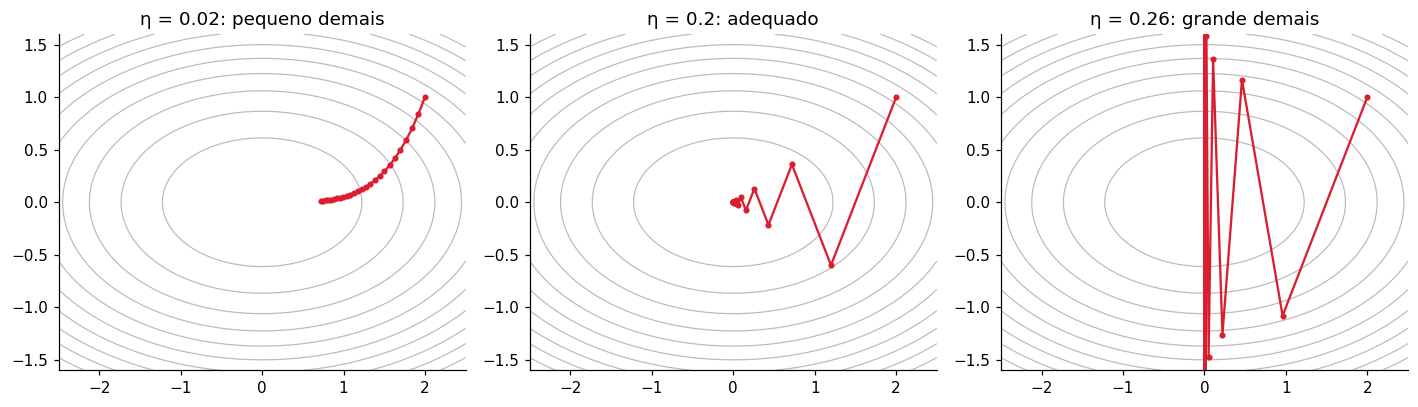

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
g1, g2 = np.meshgrid(np.linspace(-2.5, 2.5, 200), np.linspace(-1.6, 1.6, 200))
for ax, eta, titulo in zip(axs, [0.02, 0.2, 0.26], ["pequeno demais", "adequado", "grande demais"]):
    tr = descida(eta, 25)
    ax.contour(g1, g2, g1 ** 2 + 4 * g2 ** 2, levels=12, colors="#BBBBBB", linewidths=0.8)
    ax.plot(tr[:, 0], tr[:, 1], "o-", color=VERMELHO, ms=3)
    ax.set_title(f"η = {eta}: {titulo}"); ax.set_xlim(-2.5, 2.5); ax.set_ylim(-1.6, 1.6)
plt.tight_layout(); plt.show()

## 3. Inicialização

Uma função só para todas as escolhas. `metodo` pode ser `'zeros'`, `'xavier'`, `'he'` ou um número, que vira o
desvio padrão de todos os pesos (0,01 era o padrão do Lab 2).

- **Xavier** (versão com o número de entradas): σ = √(1 / n_entrada) — para tanh e sigmoid.
- **He**: σ = √(2 / n_entrada) — para ReLU, que zera metade das ativações.

In [6]:
def inicializa(camadas, metodo='he', seed=0):
    rng = np.random.default_rng(seed)
    params = {}
    for l in range(1, len(camadas)):
        n_in, n_out = camadas[l-1], camadas[l]
        if metodo == 'zeros':
            sigma = 0.0
        elif metodo == 'xavier':
            sigma = np.sqrt(1 / n_in)
        elif metodo == 'he':
            sigma = np.sqrt(2 / n_in)
        else:
            sigma = float(metodo)                  # um número: desvio padrão fixo
        params[f'W{l}'] = rng.normal(0, 1, (n_in, n_out)) * sigma
        params[f'b{l}'] = np.zeros((1, n_out))
    return params

for metodo in ['zeros', 0.01, 1.0, 'xavier', 'he']:
    p = inicializa([64, 32, 10], metodo)
    print(f"{str(metodo):>7}:  desvio de W1 = {p['W1'].std():.4f}   desvio de W2 = {p['W2'].std():.4f}")

  zeros:  desvio de W1 = 0.0000   desvio de W2 = 0.0000
   0.01:  desvio de W1 = 0.0100   desvio de W2 = 0.0099
    1.0:  desvio de W1 = 1.0014   desvio de W2 = 0.9923
 xavier:  desvio de W1 = 0.1252   desvio de W2 = 0.1754
     he:  desvio de W1 = 0.1770   desvio de W2 = 0.2481


## 4. Bloco 1 — A classe MLP

Tudo o que escrevemos em quatro aulas, organizado num objeto. Nenhuma matemática nova: o *forward* e o *backward*
são as funções acima; o que é novo é o **passo** (com momentum opcional) e o **laço de treino** em mini-lotes.

In [7]:
class MLP:
    def __init__(self, camadas, ativacao='relu', init='he', seed=0):
        self.camadas = camadas
        self.ativacao = ativacao
        self.params = inicializa(camadas, init, seed)
        self.vel = {k: np.zeros_like(v) for k, v in self.params.items()}   # para o momentum
        self.historico = {'perda': [], 'acc_treino': [], 'acc_teste': []}

    def forward(self, X):
        return forward(X, self.params, self.ativacao)

    def backward(self, Y, cache):
        return backward(Y, self.params, cache, self.ativacao)

    def passo(self, grads, eta, beta=0.0):
        for k in self.params:
            self.vel[k] = beta * self.vel[k] + grads['d' + k]       # beta = 0: só o gradiente
            self.params[k] -= eta * self.vel[k]

    def treinar(self, Xtr, Ytr, eta=0.1, epocas=60, batch=64, beta=0.0, seed=0, Xte=None, yte=None):
        rng = np.random.default_rng(seed)
        n = Xtr.shape[0]
        self.registra(Xtr, Ytr, Xte, yte)                          # época 0: antes de treinar
        for ep in range(epocas):
            ordem = rng.permutation(n)                             # embaralha a cada época
            for i in range(0, n, batch):                           # percorre os mini-lotes
                idx = ordem[i:i + batch]
                AL, cache = self.forward(Xtr[idx])
                grads = self.backward(Ytr[idx], cache)
                self.passo(grads, eta, beta)
            self.registra(Xtr, Ytr, Xte, yte)
        return self

    def registra(self, Xtr, Ytr, Xte, yte):
        AL, _ = self.forward(Xtr)
        self.historico['perda'].append(cce(Ytr, AL))
        self.historico['acc_treino'].append(np.mean(AL.argmax(axis=1) == Ytr.argmax(axis=1)))
        if Xte is not None:
            self.historico['acc_teste'].append(self.acuracia(Xte, yte))

    def prever(self, X):
        return self.forward(X)[0].argmax(axis=1)

    def acuracia(self, X, y):
        return np.mean(self.prever(X) == y)

print("classe MLP definida")

classe MLP definida


### Antes de treinar: a classe ainda passa no *gradient check*?

Reorganizar o código é uma ótima oportunidade de introduzir um bug. Repetimos o teste do Lab 3, agora através
da classe, numa rede pequena com tanh.

In [8]:
def gradient_check(modelo, X, Y, eps=1e-6):
    AL, cache = modelo.forward(X)
    grads = modelo.backward(Y, cache)
    pior = 0.0
    for chave, P in modelo.params.items():
        numerico = np.zeros_like(P)
        for ind in np.ndindex(P.shape):
            original = P[ind]
            P[ind] = original + eps;  J_mais = cce(Y, modelo.forward(X)[0])
            P[ind] = original - eps;  J_menos = cce(Y, modelo.forward(X)[0])
            P[ind] = original
            numerico[ind] = (J_mais - J_menos) / (2 * eps)
        analitico = grads['d' + chave]
        erro = np.linalg.norm(numerico - analitico) / (np.linalg.norm(numerico) + np.linalg.norm(analitico))
        pior = max(pior, erro)
    return pior

rng = np.random.default_rng(0)
X_p, Y_p = rng.normal(size=(7, 4)), one_hot(rng.integers(0, 3, 7), 3)
pior = gradient_check(MLP([4, 5, 3], 'tanh', init=1.0, seed=1), X_p, Y_p)
print(f"pior erro relativo: {pior:.1e}  ->", "APROVADO" if pior < 1e-7 else "REPROVADO")

pior erro relativo: 5.5e-10  -> APROVADO


## 5. Bloco 2 — O treino completo

Rede [64, 32, 10], ReLU, inicialização He, mini-lotes de 64, η = 0,1, 60 épocas.

In [9]:
inicio = time.time()
modelo = MLP([64, 32, 10], 'relu', init='he', seed=0)
modelo.treinar(X_tr, Y_tr, eta=0.1, epocas=60, batch=64, Xte=X_te, yte=y_te)
print(f"tempo: {time.time() - inicio:.1f} s")
print(f"perda final no treino: {modelo.historico['perda'][-1]:.4f}")
print(f"acurácia no treino: {modelo.historico['acc_treino'][-1]:.1%}   no teste: {modelo.acuracia(X_te, y_te):.1%}")

tempo: 1.3 s
perda final no treino: 0.0748
acurácia no treino: 98.8%   no teste: 97.1%


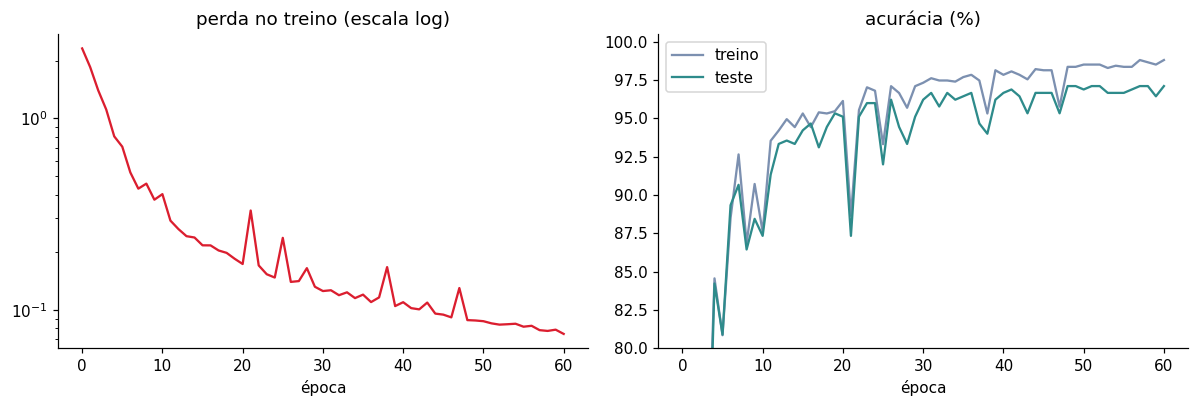

In [10]:
h = modelo.historico
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(h['perda'], color=VERMELHO); a1.set_yscale("log")
a1.set_title("perda no treino (escala log)"); a1.set_xlabel("época")
a2.plot(np.array(h['acc_treino']) * 100, color=AZUL, label="treino")
a2.plot(np.array(h['acc_teste']) * 100, color=VERDE, label="teste")
a2.set_title("acurácia (%)"); a2.set_xlabel("época"); a2.set_ylim(80, 100.5); a2.legend()
plt.tight_layout(); plt.show()

## 6. Bloco 3 — A taxa de aprendizagem

Mesma rede, mesma inicialização, mesma ordem dos lotes. Só η muda, ao longo de quatro ordens de grandeza.

In [11]:
resultados_eta = {}
with np.errstate(all="ignore"):                 # η = 10 estoura: silenciamos os avisos do NumPy
    for eta in [0.001, 0.01, 0.1, 1.0, 10.0]:
        m = MLP([64, 32, 10], 'relu', init='he', seed=0)
        m.treinar(X_tr, Y_tr, eta=eta, epocas=60, batch=64)
        resultados_eta[eta] = m
        print(f"η = {eta:<6}  perda final = {m.historico['perda'][-1]:.4f}   acurácia no teste = {m.acuracia(X_te, y_te):.1%}")

η = 0.001   perda final = 2.0033   acurácia no teste = 41.3%
η = 0.01    perda final = 0.4893   acurácia no teste = 90.0%
η = 0.1     perda final = 0.0748   acurácia no teste = 97.1%
η = 1.0     perda final = 0.0546   acurácia no teste = 95.3%
η = 10.0    perda final = 3.5190   acurácia no teste = 10.0%


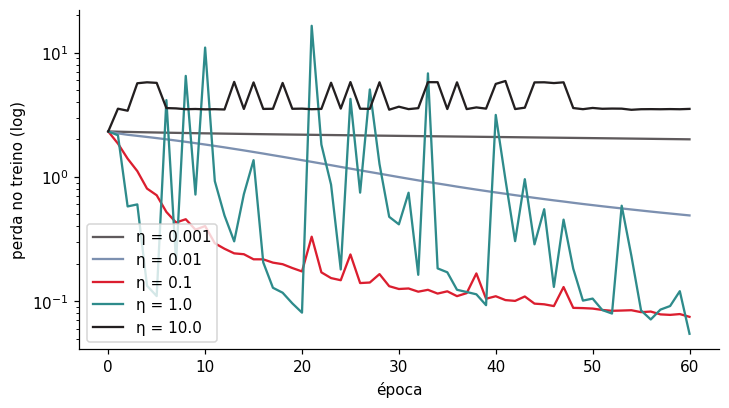

In [12]:
plt.figure(figsize=(7.5, 4))
cores = [CINZA, AZUL, VERMELHO, VERDE, TINTA]
for (eta, m), cor in zip(resultados_eta.items(), cores):
    plt.plot(m.historico['perda'], color=cor, label=f"η = {eta}")
plt.yscale("log"); plt.xlabel("época"); plt.ylabel("perda no treino (log)"); plt.legend()
plt.show()

## 7. Bloco 4 — O tamanho do lote

Mesmo η = 0,1 e as mesmas 20 épocas. Em cada época, o lote inteiro dá **1** passo, o mini-lote de 64 dá **22**
passos e o estocástico (lote de 1) dá **1.347** passos.

In [13]:
resultados_lote = {}
for nome, b in [("lote inteiro", X_tr.shape[0]), ("mini-lote de 64", 64), ("estocástico", 1)]:
    inicio = time.time()
    m = MLP([64, 32, 10], 'relu', init='he', seed=0).treinar(X_tr, Y_tr, eta=0.1, epocas=20, batch=b)
    resultados_lote[nome] = m
    passos = 20 * int(np.ceil(X_tr.shape[0] / b))
    print(f"{nome:>16}: {passos:>6} passos   {time.time() - inicio:5.1f} s   "
          f"perda = {m.historico['perda'][-1]:.4f}   acurácia no teste = {m.acuracia(X_te, y_te):.1%}")

    lote inteiro:     20 passos     0.2 s   perda = 1.8651   acurácia no teste = 50.2%
 mini-lote de 64:    440 passos     0.2 s   perda = 0.1734   acurácia no teste = 95.1%
     estocástico:  26940 passos     3.4 s   perda = 0.1249   acurácia no teste = 92.9%


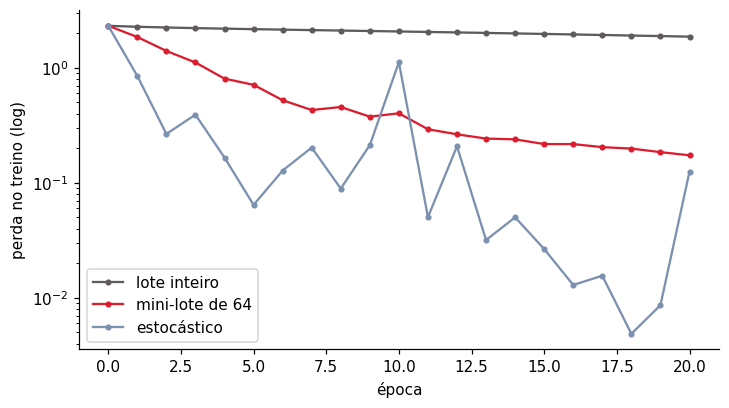

In [14]:
plt.figure(figsize=(7.5, 4))
for (nome, m), cor in zip(resultados_lote.items(), [CINZA, VERMELHO, AZUL]):
    plt.plot(m.historico['perda'], "o-", ms=3, color=cor, label=nome)
plt.yscale("log"); plt.xlabel("época"); plt.ylabel("perda no treino (log)"); plt.legend()
plt.show()

## 8. Bloco 5 — A inicialização

Mesma arquitetura, mesmo η = 0,1, mesmas 60 épocas. Só o sorteio inicial muda.

In [15]:
resultados_init = {}
for init in ['zeros', 1.0, 'xavier', 'he']:
    m = MLP([64, 32, 10], 'relu', init=init, seed=0).treinar(X_tr, Y_tr, eta=0.1, epocas=60, batch=64)
    resultados_init[init] = m
    nome = "σ = 1" if init == 1.0 else init
    print(f"{nome:>7}:  perda final = {m.historico['perda'][-1]:.4f}   acurácia no teste = {m.acuracia(X_te, y_te):.1%}")

  zeros:  perda final = 2.3028   acurácia no teste = 10.0%
  σ = 1:  perda final = 0.0800   acurácia no teste = 93.3%
 xavier:  perda final = 0.0780   acurácia no teste = 97.1%
     he:  perda final = 0.0748   acurácia no teste = 97.1%


### Por que zeros trava: o que o *backward* devolve

A pergunta para casa da Aula 3: com todos os pesos em zero, quais gradientes saem do *backward*?

In [16]:
m0 = MLP([64, 32, 10], 'relu', init='zeros')
AL, cache = m0.forward(X_tr)
grads = m0.backward(Y_tr, cache)
for k, g in grads.items():
    print(f"{k}: maior |gradiente| = {np.abs(g).max():.4f}")
print("\nprevisão da rede com pesos zero (primeira amostra):", AL[0].round(3))

dW2: maior |gradiente| = 0.0000
db2: maior |gradiente| = 0.0027
dW1: maior |gradiente| = 0.0000
db1: maior |gradiente| = 0.0000

previsão da rede com pesos zero (primeira amostra): [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]


### O sinal atravessando dez camadas

Uma rede profunda com tanh, dez camadas de 64 neurônios. Medimos o desvio padrão das ativações em cada camada e a
fração de neurônios saturados (|A| > 0,99), para três escalas iniciais.

 σ = 0,01: desvio na camada 1 = 0.0393, na camada 10 = 5.47e-12; saturados na camada 10 = 0%
   Xavier: desvio na camada 1 = 0.4113, na camada 10 = 2.09e-01; saturados na camada 10 = 0%
    σ = 1: desvio na camada 1 = 0.8930, na camada 10 = 9.47e-01; saturados na camada 10 = 73%


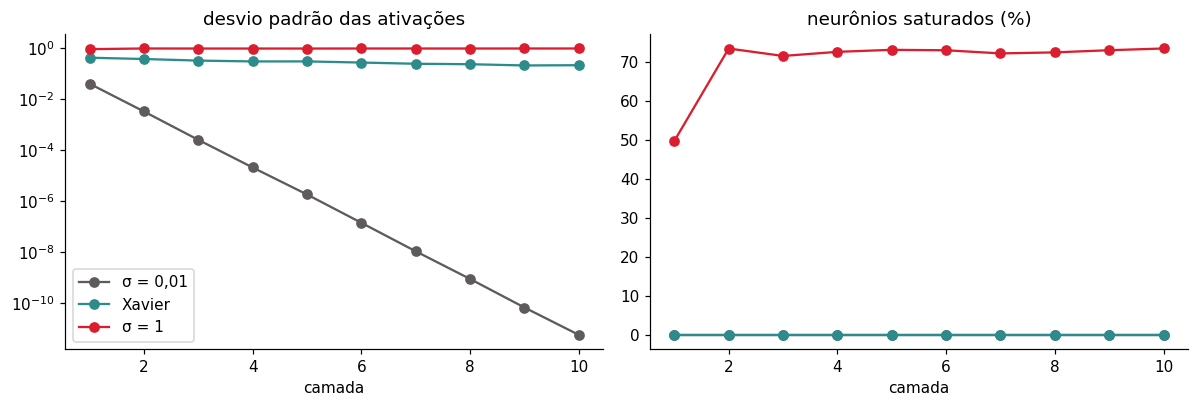

In [17]:
profunda = [64] + [64] * 10 + [10]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for metodo, cor, nome in [(0.01, CINZA, "σ = 0,01"), ('xavier', VERDE, "Xavier"), (1.0, VERMELHO, "σ = 1")]:
    p = inicializa(profunda, metodo, seed=0)
    _, cache = forward(X_tr, p, 'tanh')
    desvios = [cache[f'A{l}'].std() for l in range(1, 11)]
    saturados = [np.mean(np.abs(cache[f'A{l}']) > 0.99) for l in range(1, 11)]
    print(f"{nome:>9}: desvio na camada 1 = {desvios[0]:.4f}, na camada 10 = {desvios[-1]:.2e}; "
          f"saturados na camada 10 = {saturados[-1]:.0%}")
    axs[0].semilogy(range(1, 11), desvios, "o-", color=cor, label=nome)
    axs[1].plot(range(1, 11), np.array(saturados) * 100, "o-", color=cor, label=nome)
axs[0].set_title("desvio padrão das ativações"); axs[0].set_xlabel("camada"); axs[0].legend()
axs[1].set_title("neurônios saturados (%)"); axs[1].set_xlabel("camada")
plt.tight_layout(); plt.show()

## 9. Bloco 6 — Momentum

**v ← β v + ∇ℒ** e **θ ← θ − η v**. Com β = 0, é o gradiente descendente comum. Primeiro no vale dos slides,
depois nos dígitos.

In [18]:
def descida_momentum(eta, beta, passos, w0=(2.0, 1.0)):
    w, v = np.array(w0, dtype=float), np.zeros(2)
    trajetoria = [w.copy()]
    for t in range(passos):
        v = beta * v + grad_vale(w)
        w = w - eta * v
        trajetoria.append(w.copy())
    return np.array(trajetoria)

for beta in [0.0, 0.5]:
    tr = descida_momentum(0.02, beta, 30)
    print(f"η = 0,02, β = {beta}: perda após 30 passos = {perda_vale(tr[-1]):.4f}")

η = 0,02, β = 0.0: perda após 30 passos = 0.3455
η = 0,02, β = 0.5: perda após 30 passos = 0.0197


In [19]:
resultados_mom = {}
for beta in [0.0, 0.9]:
    m = MLP([64, 32, 10], 'relu', init='he', seed=0).treinar(X_tr, Y_tr, eta=0.01, epocas=60, batch=64, beta=beta)
    resultados_mom[beta] = m
    print(f"η = 0,01, β = {beta}:  perda final = {m.historico['perda'][-1]:.4f}   acurácia no teste = {m.acuracia(X_te, y_te):.1%}")

η = 0,01, β = 0.0:  perda final = 0.4893   acurácia no teste = 90.0%
η = 0,01, β = 0.9:  perda final = 0.0752   acurácia no teste = 97.1%


## 10. Os erros da rede

In [20]:
prev = modelo.prever(X_te)
confusao = np.zeros((10, 10), dtype=int)
for real, p in zip(y_te, prev):
    confusao[real, p] += 1
print("linhas = dígito real, colunas = previsão\n")
print(confusao)
print(f"\nacertos: {np.trace(confusao)} de {len(y_te)}")

linhas = dígito real, colunas = previsão

[[45  0  0  0  0  0  0  0  0  0]
 [ 0 45  0  0  0  1  0  0  0  0]
 [ 0  1 43  0  0  0  0  0  0  0]
 [ 0  0  0 45  0  0  0  1  0  0]
 [ 0  0  0  0 43  0  0  0  2  0]
 [ 0  1  0  0  0 44  0  1  0  0]
 [ 0  1  0  0  0  0 44  0  0  0]
 [ 0  0  0  0  0  0  0 45  0  0]
 [ 0  2  0  0  0  1  0  1 39  0]
 [ 0  0  0  0  0  1  0  0  0 44]]

acertos: 437 de 450


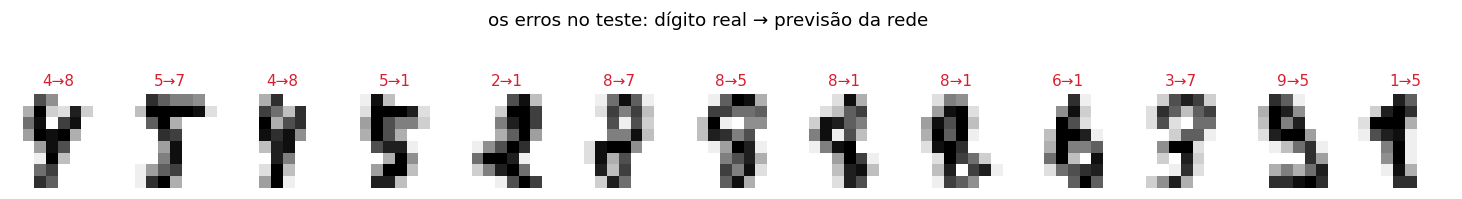

In [21]:
erros = np.where(prev != y_te)[0]
fig, axs = plt.subplots(1, len(erros), figsize=(1.3 * len(erros), 1.9))
for ax, i in zip(np.atleast_1d(axs), erros):
    ax.imshow(X_te[i].reshape(8, 8), cmap="gray_r"); ax.axis("off")
    ax.set_title(f"{y_te[i]}→{prev[i]}", color=VERMELHO, fontsize=10)
plt.suptitle("os erros no teste: dígito real → previsão da rede", y=1.12)
plt.show()

---
## Resumo

- O gradiente descendente é uma linha: **θ ← θ − η∇ℒ**. O backprop dá a direção; η, o tamanho do passo.
- η é estável abaixo de 2/c, onde c é a maior curvatura. Pequeno demais arrasta; grande demais diverge.
- Mini-lotes embaralhados a cada época: estimativa barata do gradiente, e o padrão na prática.
- Zeros travam a rede; pesos grandes saturam; Xavier (tanh, sigmoid) e He (ReLU) preservam o sinal.
- Momentum acumula a direção consistente e acelera onde o gradiente é pequeno.

Tudo isso em NumPy puro, numa classe de cerca de 50 linhas.